<a href="https://colab.research.google.com/github/GabrielHTMendes/metodo4_lbp_textura-/blob/main/metodo4_lbp_textura.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Método 4 — LBP + Análise de Textura

## 1. Objetivo

Este trabalho tem como objetivo desenvolver uma metodologia de identificação de áreas navegáveis em estradas rurais não pavimentadas utilizando Local Binary Patterns (LBP) e análise de textura.

A abordagem busca explorar diferenças nos padrões locais das superfícies para auxiliar na distinção entre regiões navegáveis e não navegáveis, inclusive em situações nas quais diferentes superfícies apresentam cores semelhantes.

## 2. Dataset

Será utilizado o dataset Off-Road Freespace Detection (ORFD), conforme definido na especificação do projeto.

## 3. Entrada e saída

**Entrada:** imagem RGB original do dataset ORFD.

**Saída:** máscara binária com as mesmas dimensões da imagem de entrada, seguindo a convenção:

* `255`: área navegável.
* `0`: área não navegável.

## 4. Avaliação

A metodologia será avaliada utilizando o Ground Truth correspondente às imagens selecionadas. As métricas de avaliação serão calculadas separadamente, conforme o contrato de integração do projeto.


# Maquina

In [3]:

import os
import sys
import platform
import subprocess
import multiprocessing

import psutil
import numpy as np
import sklearn
import skimage

print("=" * 60)
print("RELATÓRIO DO AMBIENTE COMPUTACIONAL")
print("=" * 60)

# Sistema operacional
print("\n[SISTEMA OPERACIONAL]")
print("Sistema:", platform.system())
print("Versão:", platform.version())
print("Arquitetura:", platform.machine())
print("Python:", sys.version.split()[0])

# Processador
print("\n[PROCESSADOR]")
print("Modelo:", platform.processor())
print("Núcleos lógicos:", multiprocessing.cpu_count())

try:
    resultado = subprocess.run(
        ["bash", "-lc", "lscpu"],
        capture_output=True,
        text=True,
        timeout=10
    )
    print(resultado.stdout)
except Exception as e:
    print("Não foi possível obter detalhes do processador:", e)

# Memória RAM
print("\n[MEMÓRIA RAM]")
memoria = psutil.virtual_memory()
print(f"RAM total: {memoria.total / (1024**3):.2f} GB")
print(f"RAM disponível: {memoria.available / (1024**3):.2f} GB")

# GPU
print("\n[GPU]")
try:
    resultado = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        timeout=10
    )

    if resultado.returncode == 0:
        print(resultado.stdout)
    else:
        print("GPU NVIDIA não detectada ou indisponível.")
except Exception:
    print("GPU NVIDIA não detectada ou indisponível.")

# Bibliotecas
print("\n[VERSÕES DAS BIBLIOTECAS]")
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("scikit-image:", skimage.__version__)

try:
    import cv2
    print("OpenCV:", cv2.__version__)
except ImportError:
    print("OpenCV: não instalado")

try:
    import matplotlib
    print("Matplotlib:", matplotlib.__version__)
except ImportError:
    print("Matplotlib: não instalado")

try:
    import scipy
    print("SciPy:", scipy.__version__)
except ImportError:
    print("SciPy: não instalado")

try:
    import joblib
    print("Joblib:", joblib.__version__)
except ImportError:
    print("Joblib: não instalado")

print("\n[INFORMAÇÕES DO AMBIENTE]")
print("Diretório atual:", os.getcwd())
print("Variável COLAB_GPU:", os.environ.get("COLAB_GPU", "Não definida"))

print("\n" + "=" * 60)
print("FIM DO RELATÓRIO")
print("=" * 60)



RELATÓRIO DO AMBIENTE COMPUTACIONAL

[SISTEMA OPERACIONAL]
Sistema: Linux
Versão: #1 SMP Thu Oct 22 03:07:54 UTC 2026
Arquitetura: x86_64
Python: 3.13.18

[PROCESSADOR]
Modelo: x86_64
Núcleos lógicos: 2
Architecture:                            x86_64
CPU op-mode(s):                          32-bit, 64-bit
Address sizes:                           46 bits physical, 48 bits virtual
Byte Order:                              Little Endian
CPU(s):                                  2
On-line CPU(s) list:                     0,1
Vendor ID:                               GenuineIntel
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
CPU family:                              6
Model:                                   79
Thread(s) per core:                      2
Core(s) per socket:                      1
Socket(s):                               1
Stepping:                                0
BogoMIPS:                                4400.31
Flags:                                   

# Testar existencias e intalar as bibiotecas

In [4]:
!pip -q install scikit-image scikit-learn

In [5]:
import os
import time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import local_binary_pattern

print("Bibliotecas importadas com sucesso!")
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

Bibliotecas importadas com sucesso!
OpenCV: 5.0.0
NumPy: 2.1.3


In [6]:
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import local_binary_pattern
from sklearn.cluster import KMeans

print("Bibliotecas carregadas com sucesso.")

Bibliotecas carregadas com sucesso.


In [7]:
from pathlib import Path

# Caminho do dataset no Google Drive
DATASET_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Dataset/"
    "image_data-20261028T094314Z-1-005/image_data"
)

print("Diretório de trabalho:")
print(Path.cwd())

print("\nCaminho do dataset:")
print(DATASET_DIR)

if DATASET_DIR.exists():
    print("\nPastas e arquivos disponíveis:")

    for item in sorted(DATASET_DIR.iterdir()):
        if item.is_dir():
            print(f"[PASTA] {item.name}")
        else:
            print(f"[ARQUIVO] {item.name}")

else:
    print("\nERRO: a pasta do dataset não foi encontrada.")

Diretório de trabalho:
/content

Caminho do dataset:
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data

Pastas e arquivos disponíveis:
[ARQUIVO] 1620330558332.png
[ARQUIVO] 1620330580419.png
[ARQUIVO] 1620330580612.png
[ARQUIVO] 1620330580927.png
[ARQUIVO] 1620330581106.png
[ARQUIVO] 1620330581706.png
[ARQUIVO] 1620330581808.png
[ARQUIVO] 1620330582322.png
[ARQUIVO] 1620330583520.png
[ARQUIVO] 1620330585007.png
[ARQUIVO] 1620330585508.png
[ARQUIVO] 1620330586001.png
[ARQUIVO] 1620330586704.png
[ARQUIVO] 1620330587014.png
[ARQUIVO] 1620330587633.png
[ARQUIVO] 1620330588514.png
[ARQUIVO] 1620330588913.png
[ARQUIVO] 1620330589529.png
[ARQUIVO] 1620330590213.png
[ARQUIVO] 1620330591029.png
[ARQUIVO] 1620330591335.png
[ARQUIVO] 1620330591814.png
[ARQUIVO] 1620330592217.png
[ARQUIVO] 1620330593123.png
[ARQUIVO] 1620330594036.png
[ARQUIVO] 1620330594429.png
[ARQUIVO] 1620330594726.png
[ARQUIVO] 1620330596438.png
[ARQUIVO] 1620330597114.png
[ARQUIVO] 1

In [8]:
extensoes = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

imagens = [
    arquivo
    for arquivo in DATASET_DIR.rglob("*")
    if arquivo.is_file()
    and arquivo.suffix.lower() in extensoes
]

print(f"Total de imagens encontradas: {len(imagens)}")

print("\nPrimeiras imagens:")

for imagem in imagens[:10]:
    print(imagem)

Total de imagens encontradas: 1416

Primeiras imagens:
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data/1623728556459.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data/1623728556365.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data/1623728554962.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data/1623728558962.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data/1623728554762.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data/1623728554162.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data/1623728553762.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data/1623724477146.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-2026102

Imagem selecionada: 1623728556459.png
Dimensões: (720, 1280, 3)
Tipo de dado: uint8


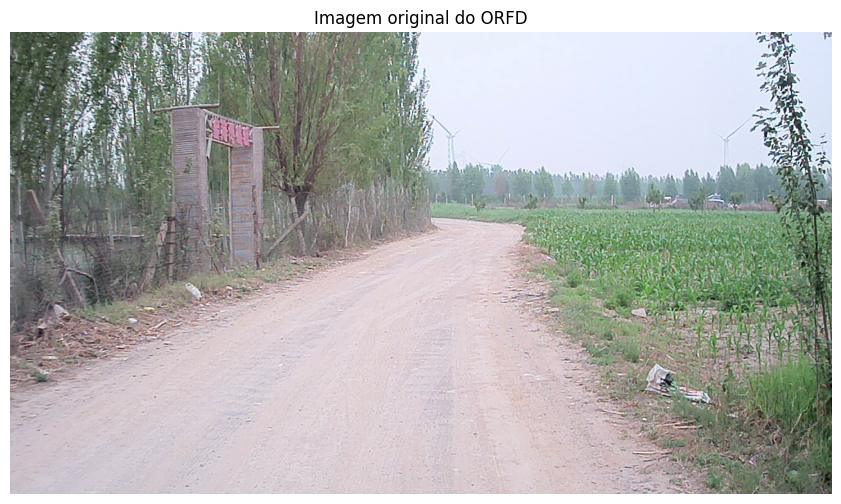

In [9]:
# Selecionar uma imagem do dataset
caminho_imagem = imagens[0]

# Carregar a imagem
imagem_bgr = cv2.imread(str(caminho_imagem))

if imagem_bgr is None:
    raise ValueError(f"Não foi possível carregar: {caminho_imagem}")

# Converter BGR para RGB
imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)

# Converter para escala de cinza
imagem_cinza = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2GRAY)

print("Imagem selecionada:", caminho_imagem.name)
print("Dimensões:", imagem_rgb.shape)
print("Tipo de dado:", imagem_rgb.dtype)

# Visualizar
plt.figure(figsize=(12, 6))
plt.imshow(imagem_rgb)
plt.title("Imagem original do ORFD")
plt.axis("off")
plt.show()

Mapa LBP calculado!
Dimensões: (720, 1280)
Tipo de dado: float64


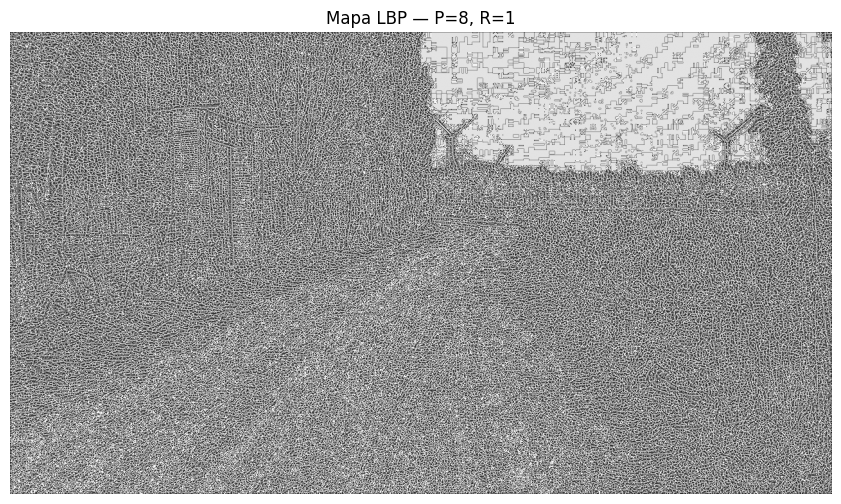

In [10]:
# Parâmetros iniciais do LBP
P = 8
R = 1

# Calcular o mapa LBP
lbp = local_binary_pattern(
    imagem_cinza,
    P=P,
    R=R,
    method="uniform"
)

print("Mapa LBP calculado!")
print("Dimensões:", lbp.shape)
print("Tipo de dado:", lbp.dtype)

# Visualizar o mapa de textura
plt.figure(figsize=(12, 6))
plt.imshow(lbp, cmap="gray")
plt.title(f"Mapa LBP — P={P}, R={R}")
plt.axis("off")
plt.show()

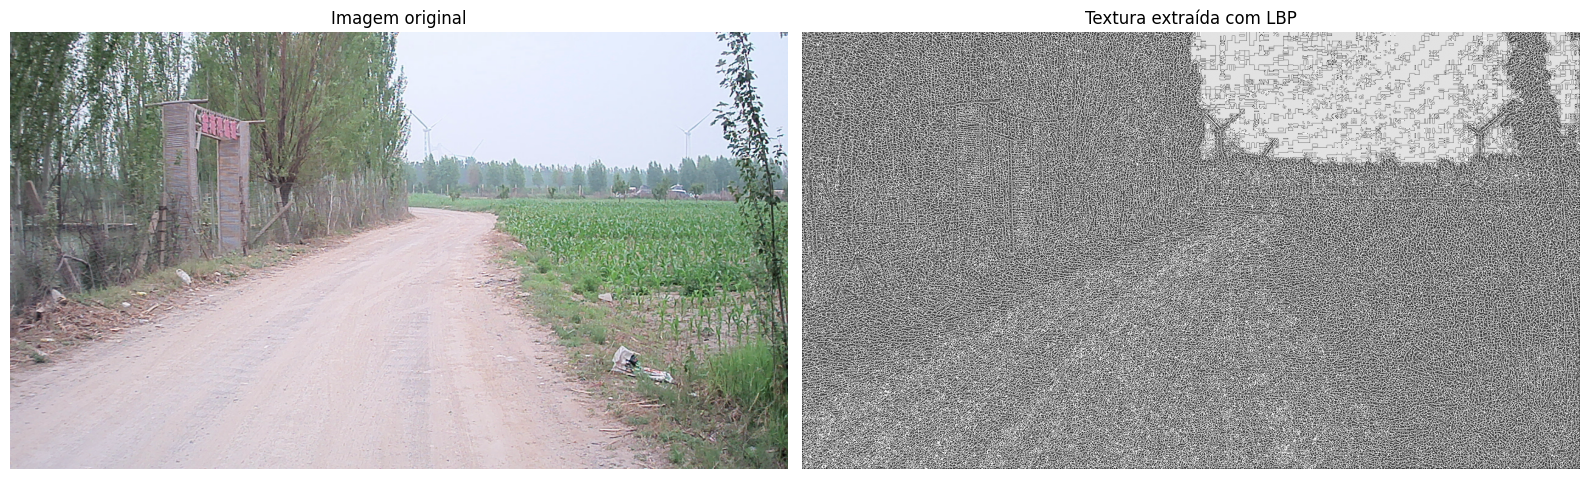

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].imshow(imagem_rgb)
axes[0].set_title("Imagem original")
axes[0].axis("off")

axes[1].imshow(lbp, cmap="gray")
axes[1].set_title("Textura extraída com LBP")
axes[1].axis("off")

plt.tight_layout()
plt.show()

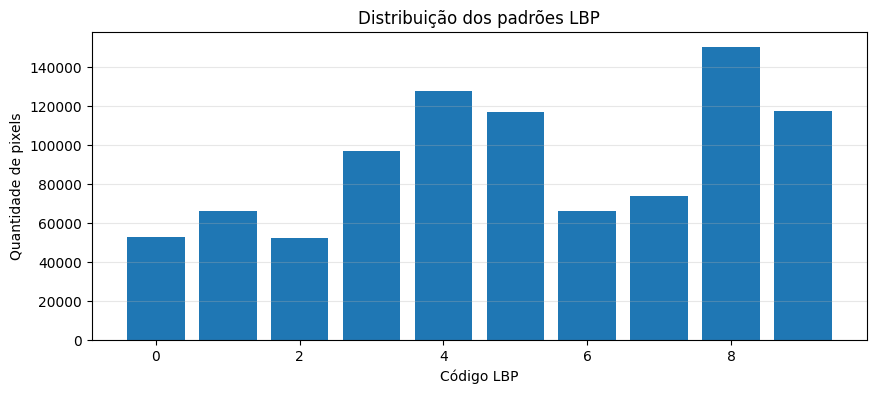

In [12]:
# Histograma dos padrões LBP
valores, contagens = np.unique(lbp, return_counts=True)

plt.figure(figsize=(10, 4))
plt.bar(valores, contagens)
plt.title("Distribuição dos padrões LBP")
plt.xlabel("Código LBP")
plt.ylabel("Quantidade de pixels")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [13]:
# Caminho das anotações do ORFD
GT_DIR = Path(
    "/content/drive/MyDrive/Colab Notebooks/Dataset/"
    "image_data-20261028T094314Z-1-005/"
    "gt_image-20261028T113702Z-1-001"
)

print("Pasta do Ground Truth:")
print(GT_DIR)

if GT_DIR.exists():
    print("\nConteúdo da pasta:")

    for item in sorted(GT_DIR.iterdir()):
        if item.is_dir():
            print(f"[PASTA] {item.name}")
        else:
            print(f"[ARQUIVO] {item.name}")
else:
    print("ERRO: pasta do Ground Truth não encontrada.")

Pasta do Ground Truth:
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/gt_image-20261028T113702Z-1-001

Conteúdo da pasta:
[PASTA] gt_image


In [14]:
# Extensões de imagem aceitas
extensoes = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}

ground_truths = sorted([
    arquivo
    for arquivo in GT_DIR.rglob("*")
    if arquivo.is_file()
    and arquivo.suffix.lower() in extensoes
])

print(f"Total de arquivos de imagem encontrados: {len(ground_truths)}")

print("\nPrimeiros arquivos:")

for arquivo in ground_truths[:10]:
    print(arquivo)

Total de arquivos de imagem encontrados: 8392

Primeiros arquivos:
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/gt_image-20261028T113702Z-1-001/gt_image/1619778700681_fillcolor.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/gt_image-20261028T113702Z-1-001/gt_image/1619778700776_fillcolor.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/gt_image-20261028T113702Z-1-001/gt_image/1619778700874_fillcolor.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/gt_image-20261028T113702Z-1-001/gt_image/1619778700973_fillcolor.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/gt_image-20261028T113702Z-1-001/gt_image/1619778701077_fillcolor.png
/content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/gt_image-20261028T113702Z-1-001/gt_image/1619778701150_fillcolor.png
/content/drive/MyDrive/Colab Note

Arquivo: 1619778700681_fillcolor.png
Dimensões: (720, 1280)
Tipo: uint8
Valores de pixels: [  0 255]


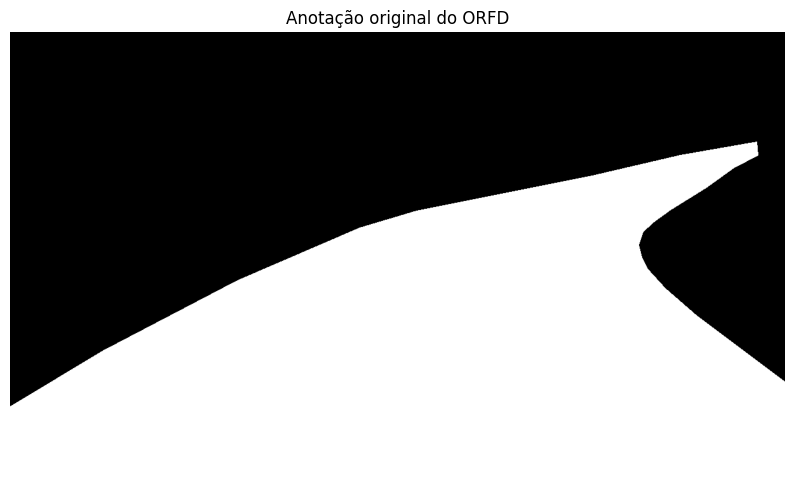

In [15]:
if ground_truths:
    caminho_gt = ground_truths[0]

    gt_original = cv2.imread(
        str(caminho_gt),
        cv2.IMREAD_UNCHANGED
    )

    if gt_original is None:
        raise ValueError("Não foi possível carregar a anotação.")

    print("Arquivo:", caminho_gt.name)
    print("Dimensões:", gt_original.shape)
    print("Tipo:", gt_original.dtype)
    print("Valores de pixels:", np.unique(gt_original)[:30])

    plt.figure(figsize=(10, 6))
    plt.imshow(gt_original, cmap="gray")
    plt.title("Anotação original do ORFD")
    plt.axis("off")
    plt.show()

else:
    print("Nenhuma imagem foi encontrada na pasta.")

========== DATASET ==========
Imagens RGB encontradas: 1416
Anotações encontradas: 8392

========== EXEMPLO DE ANOTAÇÃO ==========
Arquivo: 1619778700681_fillcolor.png
Dimensões: (720, 1280)
Tipo de dado: uint8

Valores dos pixels e respectivas quantidades:
Valor 0: 492843 pixels
Valor 255: 428757 pixels

========== VISUALIZAÇÃO ==========


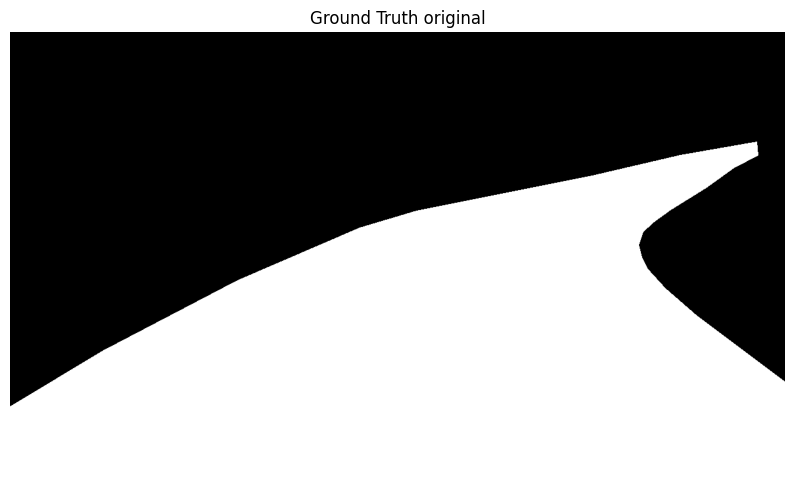

In [16]:

# Verificar a quantidade de imagens e as classes do Ground Truth

print("========== DATASET ==========")
print("Imagens RGB encontradas:", len(imagens))
print("Anotações encontradas:", len(ground_truths))

print("\n========== EXEMPLO DE ANOTAÇÃO ==========")

caminho_gt = ground_truths[0]
gt = cv2.imread(str(caminho_gt), cv2.IMREAD_UNCHANGED)

if gt is None:
    raise ValueError("Não foi possível carregar a anotação.")

print("Arquivo:", caminho_gt.name)
print("Dimensões:", gt.shape)
print("Tipo de dado:", gt.dtype)

if gt.ndim == 2:
    valores, quantidades = np.unique(gt, return_counts=True)

    print("\nValores dos pixels e respectivas quantidades:")
    for valor, quantidade in zip(valores, quantidades):
        print(f"Valor {valor}: {quantidade} pixels")

elif gt.ndim == 3:
    cores, quantidades = np.unique(
        gt.reshape(-1, gt.shape[2]),
        axis=0,
        return_counts=True
    )

    print("\nCores encontradas e respectivas quantidades:")
    for cor, quantidade in zip(cores[:30], quantidades[:30]):
        print(f"Cor {cor.tolist()}: {quantidade} pixels")

    if len(cores) > 30:
        print(f"... e outras {len(cores) - 30} cores.")

print("\n========== VISUALIZAÇÃO ==========")

plt.figure(figsize=(10, 6))

if gt.ndim == 2:
    plt.imshow(gt, cmap="gray")
else:
    # OpenCV carrega imagens coloridas em BGR;
    # converter para RGB para exibição correta.
    plt.imshow(cv2.cvtColor(gt, cv2.COLOR_BGR2RGB))

plt.title("Ground Truth original")
plt.axis("off")
plt.show()



In [17]:
from collections import Counter

print("========== ESTRUTURA DO GROUND TRUTH ==========")

for item in sorted(GT_DIR.iterdir()):
    if item.is_dir():
        arquivos = [
            f for f in item.rglob("*")
            if f.is_file()
        ]
        print(f"Pasta: {item.name} | Arquivos: {len(arquivos)}")
    else:
        print(f"Arquivo: {item.name}")

print("\n========== TIPOS DE ANOTAÇÃO ==========")

nomes_gt = [arquivo.name for arquivo in ground_truths]

print("Total de anotações:", len(nomes_gt))
print("Anotações com fillcolor:", sum(
    "fillcolor" in nome.lower() for nome in nomes_gt
))

print("\nExemplos de anotações:")
for arquivo in ground_truths[:20]:
    print(arquivo.name)

print("\n========== EXEMPLOS DE IMAGENS RGB ==========")

for arquivo in imagens[:20]:
    print(arquivo.name)

========== ESTRUTURA DO GROUND TRUTH ==========
Pasta: gt_image | Arquivos: 8392

========== TIPOS DE ANOTAÇÃO ==========
Total de anotações: 8392
Anotações com fillcolor: 8392

Exemplos de anotações:
1619778700681_fillcolor.png
1619778700776_fillcolor.png
1619778700874_fillcolor.png
1619778700973_fillcolor.png
1619778701077_fillcolor.png
1619778701150_fillcolor.png
1619778701260_fillcolor.png
1619778701368_fillcolor.png
1619778701457_fillcolor.png
1619778701572_fillcolor.png
1619778701668_fillcolor.png
1619778701748_fillcolor.png
1619778701850_fillcolor.png
1619778701987_fillcolor.png
1619778702054_fillcolor.png
1619778702164_fillcolor.png
1619778702272_fillcolor.png
1619778702352_fillcolor.png
1619778702456_fillcolor.png
1619778702571_fillcolor.png

========== EXEMPLOS DE IMAGENS RGB ==========
1623728556459.png
1623728556365.png
1623728554962.png
1623728558962.png
1623728554762.png
1623728554162.png
1623728553762.png
1623724477146.png
1623724479146.png
1623724478303.png
162372447548

In [18]:
from pathlib import Path

# Criar índices de imagens RGB e anotações pelo nome do arquivo
indice_rgb = {
    arquivo.stem: arquivo
    for arquivo in imagens
}

indice_gt = {
    arquivo.name.replace("_fillcolor.png", ""): arquivo
    for arquivo in ground_truths
}

# Verificar correspondências exatas
pares = []

for nome, caminho_rgb in indice_rgb.items():
    if nome in indice_gt:
        pares.append((caminho_rgb, indice_gt[nome]))

print("========== CORRESPONDÊNCIA ==========")
print("Imagens RGB:", len(imagens))
print("Máscaras Ground Truth:", len(ground_truths))
print("Pares encontrados:", len(pares))

print("\n========== EXEMPLOS DE PARES ==========")

for rgb, gt in pares[:10]:
    print(f"RGB: {rgb.name} | GT: {gt.name}")

print("\n========== EXEMPLO SEM CORRESPONDÊNCIA ==========")

if len(pares) < len(imagens):
    nomes_pares = {rgb.stem for rgb, gt in pares}

    sem_par = [
        arquivo for arquivo in imagens
        if arquivo.stem not in nomes_pares
    ]

    for arquivo in sem_par[:10]:
        print(arquivo.name)
else:
    print("Todas as imagens possuem correspondência exata.")



========== CORRESPONDÊNCIA ==========
Imagens RGB: 1416
Máscaras Ground Truth: 8392
Pares encontrados: 1416

========== EXEMPLOS DE PARES ==========
RGB: 1623728556459.png | GT: 1623728556459_fillcolor.png
RGB: 1623728556365.png | GT: 1623728556365_fillcolor.png
RGB: 1623728554962.png | GT: 1623728554962_fillcolor.png
RGB: 1623728558962.png | GT: 1623728558962_fillcolor.png
RGB: 1623728554762.png | GT: 1623728554762_fillcolor.png
RGB: 1623728554162.png | GT: 1623728554162_fillcolor.png
RGB: 1623728553762.png | GT: 1623728553762_fillcolor.png
RGB: 1623724477146.png | GT: 1623724477146_fillcolor.png
RGB: 1623724479146.png | GT: 1623724479146_fillcolor.png
RGB: 1623724478303.png | GT: 1623724478303_fillcolor.png

========== EXEMPLO SEM CORRESPONDÊNCIA ==========
Todas as imagens possuem correspondência exata.


Imagem: 1623728556459.png
Ground Truth: 1623728556459_fillcolor.png
Dimensões RGB: (720, 1280, 3)
Dimensões GT: (720, 1280)
Valores da máscara: [  0 128 255]


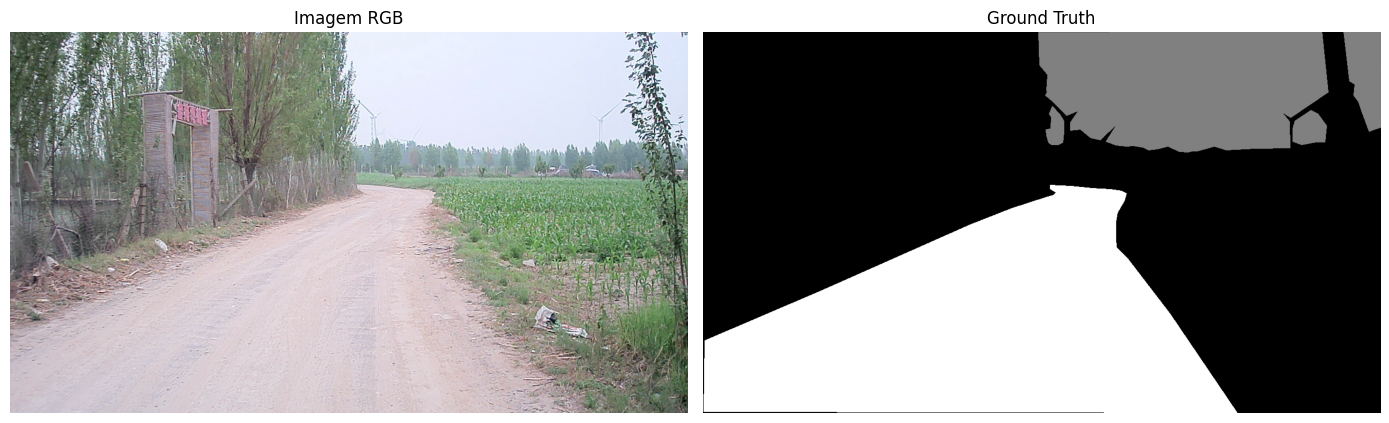

In [19]:

import cv2
import matplotlib.pyplot as plt
import numpy as np

if not pares:
    print("Nenhum par encontrado. Precisamos investigar os nomes dos arquivos.")
else:
    rgb_path, gt_path = pares[0]

    rgb = cv2.imread(str(rgb_path))
    rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

    gt = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE)

    print("Imagem:", rgb_path.name)
    print("Ground Truth:", gt_path.name)
    print("Dimensões RGB:", rgb.shape)
    print("Dimensões GT:", gt.shape)
    print("Valores da máscara:", np.unique(gt))

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(rgb)
    plt.title("Imagem RGB")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(gt, cmap="gray", vmin=0, vmax=255)
    plt.title("Ground Truth")
    plt.axis("off")

    plt.tight_layout()
    plt.show()



In [20]:
import cv2
import numpy as np

rgb_path, gt_path = pares[0]

gt = cv2.imread(str(gt_path), cv2.IMREAD_GRAYSCALE)

valores, quantidades = np.unique(gt, return_counts=True)
total_pixels = gt.size

print("========== DISTRIBUIÇÃO DAS CLASSES ==========")

for valor, quantidade in zip(valores, quantidades):
    percentual = quantidade / total_pixels * 100
    print(
        f"Valor {valor}: {quantidade:,} pixels "
        f"({percentual:.2f}%)"
    )

print("\nTotal de pixels:", total_pixels)

========== DISTRIBUIÇÃO DAS CLASSES ==========
Valor 0: 528,867 pixels (57.39%)
Valor 128: 121,440 pixels (13.18%)
Valor 255: 271,293 pixels (29.44%)

Total de pixels: 921600


In [21]:
print("========== ESTRUTURA DAS PASTAS ==========")

for pasta in sorted(DATASET_DIR.parent.parent.iterdir()):
    if pasta.is_dir():
        quantidade = sum(1 for item in pasta.rglob("*") if item.is_file())
        print(f"{pasta.name}: {quantidade} arquivos")

print("\n========== CAMINHOS DO PROJETO ==========")
print("Imagens RGB:", DATASET_DIR)
print("Ground Truth:", GT_DIR)

========== ESTRUTURA DAS PASTAS ==========
image_data-20261028T094314Z-1-005: 9808 arquivos

========== CAMINHOS DO PROJETO ==========
Imagens RGB: /content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/image_data
Ground Truth: /content/drive/MyDrive/Colab Notebooks/Dataset/image_data-20261028T094314Z-1-005/gt_image-20261028T113702Z-1-001


# Processar imagem A

In [22]:
from sklearn.model_selection import train_test_split

# Conferir os pares de imagens e máscaras
print("Total de pares:", len(pares))

# Separar treinamento e teste
pares_treino, pares_teste = train_test_split(
    pares,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Imagens para treinamento:", len(pares_treino))
print("Imagens para teste:", len(pares_teste))

Total de pares: 1416
Imagens para treinamento: 1132
Imagens para teste: 284


In [23]:

import cv2
import time
import numpy as np

from skimage.feature import local_binary_pattern
from sklearn.ensemble import RandomForestClassifier
from tqdm.auto import tqdm


# Parâmetros do método
P = 8
R = 1
JANELA = 15

PIXELS_POR_IMAGEM = 1500
RANDOM_STATE = 42


def extrair_caracteristicas(imagem_rgb):
    """
    Extrai características LBP e estatísticas locais de textura.
    Recebe uma imagem RGB.
    Retorna uma matriz de características por pixel.
    """

    cinza = cv2.cvtColor(imagem_rgb, cv2.COLOR_RGB2GRAY)

    lbp = local_binary_pattern(
        cinza,
        P=P,
        R=R,
        method="uniform"
    ).astype(np.float32)

    # Normalização das características LBP
    lbp /= (P + 2)

    # Estatísticas locais
    media = cv2.blur(lbp, (JANELA, JANELA))
    media_quadratica = cv2.blur(lbp * lbp, (JANELA, JANELA))

    desvio = np.sqrt(
        np.maximum(media_quadratica - media * media, 0)
    )

    # Intensidade normalizada
    intensidade = cinza.astype(np.float32) / 255.0

    # Combinar características
    caracteristicas = np.stack(
        [lbp, media, desvio, intensidade],
        axis=-1
    )

    return caracteristicas


def carregar_rgb(caminho):
    imagem = cv2.imread(str(caminho))

    if imagem is None:
        raise ValueError(f"Não foi possível carregar: {caminho}")

    return cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)


def carregar_gt(caminho):
    gt = cv2.imread(str(caminho), cv2.IMREAD_GRAYSCALE)

    if gt is None:
        raise ValueError(f"Não foi possível carregar: {caminho}")

    # Classe navegável = 1; demais classes = 0
    return (gt == 255).astype(np.uint8)


# ============================================================
# TREINAMENTO DO MODELO
# ============================================================

# Coletar amostras das imagens de treinamento
X_amostras = []
y_amostras = []

rng = np.random.default_rng(RANDOM_STATE)

print("Extraindo características das imagens de treinamento...")

for rgb_path, gt_path in tqdm(pares_treino):

    imagem = carregar_rgb(rgb_path)
    gt = carregar_gt(gt_path)

    if imagem.shape[:2] != gt.shape:
        raise ValueError(
            f"Dimensões incompatíveis: {rgb_path.name}"
        )

    caracteristicas = extrair_caracteristicas(imagem)

    X = caracteristicas.reshape(-1, 4)
    y = gt.reshape(-1)

    # Amostrar pixels para reduzir o custo computacional
    quantidade = min(PIXELS_POR_IMAGEM, len(y))

    indices = rng.choice(
        len(y),
        size=quantidade,
        replace=False
    )

    X_amostras.append(X[indices])
    y_amostras.append(y[indices])


X_treino = np.concatenate(X_amostras, axis=0)
y_treino = np.concatenate(y_amostras, axis=0)

print("\nAmostras coletadas:", len(y_treino))
print("Pixels navegáveis:", np.sum(y_treino == 1))
print("Pixels não navegáveis:", np.sum(y_treino == 0))


# Treinar o classificador
modelo_lbp = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=3,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    class_weight="balanced_subsample"
)

print("\nTreinando Random Forest...")
inicio_treino = time.perf_counter()

modelo_lbp.fit(X_treino, y_treino)

tempo_treino = time.perf_counter() - inicio_treino

print(f"Treinamento concluído em {tempo_treino:.2f} segundos.")


# ============================================================
# FUNÇÃO OFICIAL DO MÉTODO 4
# ============================================================

def processar(imagem):
    """
    Recebe uma imagem RGB e retorna:
    - mascara: imagem binária uint8, com 0 e 255;
    - tempo_ms: tempo de processamento;
    - parametros: parâmetros utilizados.
    """

    if imagem is None or imagem.ndim != 3 or imagem.shape[2] != 3:
        raise ValueError("A entrada deve ser uma imagem RGB válida.")

    inicio = time.perf_counter()

    # Extrair características de cada pixel
    caracteristicas = extrair_caracteristicas(imagem)

    altura, largura = imagem.shape[:2]
    X = caracteristicas.reshape(-1, 4)

    # Classificar os pixels
    predicoes = modelo_lbp.predict(X)

    # Gerar máscara: 255 = navegável; 0 = não navegável
    mascara = (
        predicoes.reshape(altura, largura) * 255
    ).astype(np.uint8)

    tempo_ms = (time.perf_counter() - inicio) * 1000

    return {
        "mascara": mascara,
        "tempo_ms": tempo_ms,
        "parametros": {
            "metodo": "LBP + análise de textura + Random Forest",
            "P": P,
            "R": R,
            "janela": JANELA,
            "pixels_por_imagem_treinamento": PIXELS_POR_IMAGEM,
            "classificador": "Random Forest"
        }
    }



Extraindo características das imagens de treinamento...


  0%|          | 0/1132 [00:00<?, ?it/s]


Amostras coletadas: 1698000
Pixels navegáveis: 456935
Pixels não navegáveis: 1241065

Treinando Random Forest...
Treinamento concluído em 557.48 segundos.


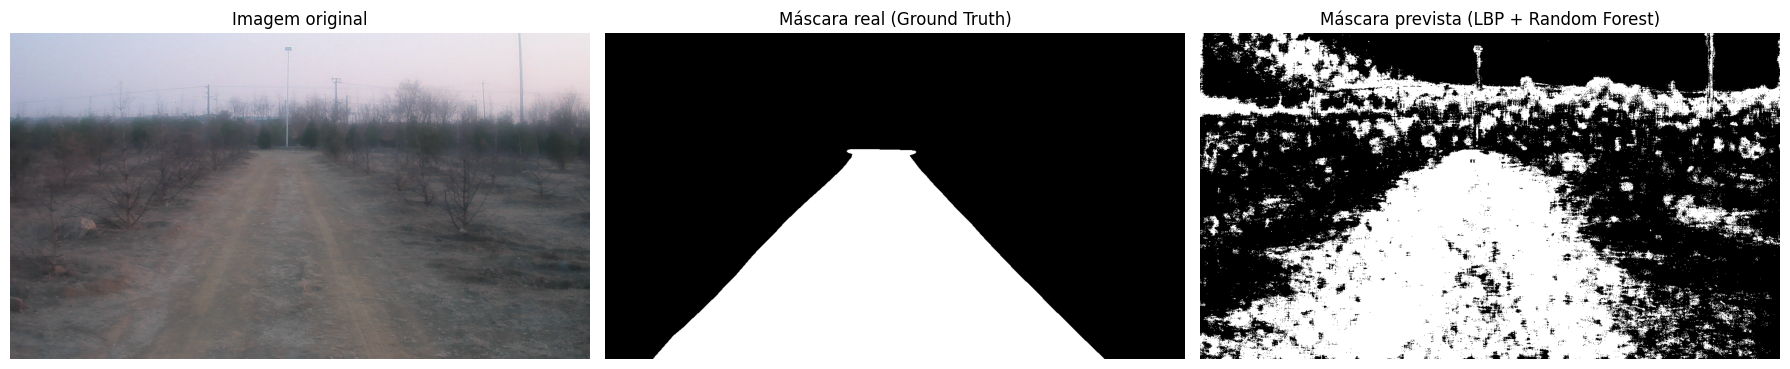

Imagem: 1620373576803.png
Tempo de processamento: 13176.92 ms


In [24]:

import matplotlib.pyplot as plt
import cv2
import numpy as np

# Selecionar uma imagem do conjunto de teste
caminho_rgb, caminho_gt = pares_teste[0]

# Carregar imagem original
imagem = carregar_rgb(caminho_rgb)

# Carregar máscara real
mascara_real = cv2.imread(
    str(caminho_gt),
    cv2.IMREAD_GRAYSCALE
)

# Converter a máscara real:
# 255 = área navegável
# 0 e 128 = demais classes
mascara_real = (mascara_real == 255).astype(np.uint8) * 255

# Executar o método LBP + Random Forest
resultado = processar(imagem)
mascara_prevista = resultado["mascara"]

# Exibir resultados
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(imagem)
plt.title("Imagem original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mascara_real, cmap="gray", vmin=0, vmax=255)
plt.title("Máscara real (Ground Truth)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mascara_prevista, cmap="gray", vmin=0, vmax=255)
plt.title("Máscara prevista (LBP + Random Forest)")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Imagem:", caminho_rgb.name)
print(f"Tempo de processamento: {resultado['tempo_ms']:.2f} ms")



In [ ]:

import os
import time
import cv2
import numpy as np

from joblib import Parallel, delayed
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    jaccard_score
)
from tqdm.auto import tqdm

# Configuração de paralelismo
N_JOBS = -1  # Utilizar os núcleos disponíveis

# Permitir que o Random Forest paralelize as predições
modelo_lbp.n_jobs = N_JOBS


def avaliar_imagem(par):
    caminho_rgb, caminho_gt = par

    # Carregar imagem e máscara real
    imagem = carregar_rgb(caminho_rgb)
    gt = carregar_gt(caminho_gt)

    # Executar o método
    resultado = processar(imagem)

    y_real = gt.ravel()
    y_pred = (resultado["mascara"].ravel() == 255).astype(np.uint8)

    # Calcular métricas
    return {
        "iou": jaccard_score(y_real, y_pred, zero_division=0),
        "precisao": precision_score(y_real, y_pred, zero_division=0),
        "recall": recall_score(y_real, y_pred, zero_division=0),
        "f1": f1_score(y_real, y_pred, zero_division=0),
        "tempo_ms": resultado["tempo_ms"],
        "imagem": caminho_rgb.name
    }


print("Iniciando avaliação paralela...")
print(f"Imagens de teste: {len(pares_teste)}")
print(f"Núcleos lógicos disponíveis: {os.cpu_count()}")

inicio_total = time.perf_counter()

resultados = Parallel(
    n_jobs=N_JOBS,
    backend="threading",
    prefer="threads"
)(
    delayed(avaliar_imagem)(par)
    for par in tqdm(pares_teste, desc="Avaliando imagens")
)

tempo_total = time.perf_counter() - inicio_total

# Organizar resultados
iou_lista = [r["iou"] for r in resultados]
precisao_lista = [r["precisao"] for r in resultados]
recall_lista = [r["recall"] for r in resultados]
f1_lista = [r["f1"] for r in resultados]
tempos = [r["tempo_ms"] for r in resultados]

print("\n" + "=" * 48)
print("RESULTADOS — LBP + TEXTURA + RANDOM FOREST")
print("=" * 48)
print(f"Imagens avaliadas:          {len(resultados)}")
print(f"IoU médio:                  {np.mean(iou_lista):.4f}")
print(f"Precisão média:             {np.mean(precisao_lista):.4f}")
print(f"Recall médio:               {np.mean(recall_lista):.4f}")
print(f"F1-score médio:             {np.mean(f1_lista):.4f}")
print(f"Inferência média por imagem: {np.mean(tempos):.2f} ms")
print(f"Tempo total da avaliação:   {tempo_total:.2f} s")
print("=" * 48)



Iniciando avaliação paralela...
Imagens de teste: 284
Núcleos lógicos disponíveis: 2


Avaliando imagens:   0%|          | 0/284 [00:00<?, ?it/s]

In [ ]:
import time
import numpy as np

# Selecionar uma imagem do conjunto de teste
caminho_rgb, caminho_gt = pares_teste[0]
imagem = carregar_rgb(caminho_rgb)

print("Imagem:", caminho_rgb.name)
print("Dimensões:", imagem.shape)

# Medir extração de características
inicio = time.perf_counter()
caracteristicas = extrair_caracteristicas(imagem)
tempo_caracteristicas = time.perf_counter() - inicio

# Preparar entrada do classificador
X = caracteristicas.reshape(-1, 4)

# Medir predição
inicio = time.perf_counter()
predicoes = modelo_lbp.predict(X)
tempo_predicao = time.perf_counter() - inicio

print("\n===== DIAGNÓSTICO DE DESEMPENHO =====")
print(f"Extração de características: {tempo_caracteristicas:.2f} s")
print(f"Predição Random Forest:      {tempo_predicao:.2f} s")
print(f"Tempo total:                 {tempo_caracteristicas + tempo_predicao:.2f} s")
print(f"Pixels processados:          {len(predicoes):,}")
print(f"Características por pixel:   {X.shape[1]}")

In [ ]:

import cv2
import time
import numpy as np
from threadpoolctl import threadpool_limits

# Selecionar uma imagem do conjunto de teste
caminho_rgb, caminho_gt = pares_teste[0]
imagem_original = carregar_rgb(caminho_rgb)

# Usar duas threads, configuração mais rápida no teste anterior
modelo_lbp.n_jobs = 2

print("Comparando resoluções de inferência...\n")

for escala in [1.0, 0.5, 0.25]:
    if escala == 1.0:
        imagem = imagem_original
    else:
        nova_largura = int(imagem_original.shape[1] * escala)
        nova_altura = int(imagem_original.shape[0] * escala)

        imagem = cv2.resize(
            imagem_original,
            (nova_largura, nova_altura),
            interpolation=cv2.INTER_AREA
        )

    # Medir extração e predição
    inicio = time.perf_counter()

    caracteristicas = extrair_caracteristicas(imagem)
    X_teste = caracteristicas.reshape(-1, 4)

    with threadpool_limits(limits=2):
        predicoes = modelo_lbp.predict(X_teste)

    tempo = time.perf_counter() - inicio

    mascara = predicoes.reshape(imagem.shape[:2])

    print(f"Escala: {escala * 100:.0f}%")
    print(f"Resolução: {imagem.shape[1]} x {imagem.shape[0]}")
    print(f"Pixels classificados: {X_teste.shape[0]:,}")
    print(f"Tempo total: {tempo:.2f} segundos\n")



In [ ]:

import cv2
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    jaccard_score
)
from threadpoolctl import threadpool_limits

# Selecionar uma imagem do conjunto de teste
caminho_rgb, caminho_gt = pares_teste[0]

imagem_original = carregar_rgb(caminho_rgb)
gt_original = carregar_gt(caminho_gt)

# Utilizar duas threads
modelo_lbp.n_jobs = 2

escalas = [1.0, 0.5, 0.25]
resultados_resolucao = []

fig, eixos = plt.subplots(2, 3, figsize=(16, 9))

for i, escala in enumerate(escalas):

    # Redimensionar a imagem
    if escala == 1.0:
        imagem = imagem_original.copy()
    else:
        largura = int(imagem_original.shape[1] * escala)
        altura = int(imagem_original.shape[0] * escala)

        imagem = cv2.resize(
            imagem_original,
            (largura, altura),
            interpolation=cv2.INTER_AREA
        )

    # Executar extração e predição
    inicio = time.perf_counter()

    caracteristicas = extrair_caracteristicas(imagem)
    X_teste = caracteristicas.reshape(-1, 4)

    with threadpool_limits(limits=2):
        predicoes = modelo_lbp.predict(X_teste)

    tempo = time.perf_counter() - inicio

    mascara_reduzida = predicoes.reshape(imagem.shape[:2]).astype(np.uint8)

    # Redimensionar a previsão para o tamanho original
    mascara_ampliada = cv2.resize(
        mascara_reduzida,
        (imagem_original.shape[1], imagem_original.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    # Converter para representação binária
    y_real = gt_original.ravel()
    y_pred = mascara_ampliada.ravel()

    iou = jaccard_score(y_real, y_pred, zero_division=0)
    precisao = precision_score(y_real, y_pred, zero_division=0)
    recall = recall_score(y_real, y_pred, zero_division=0)
    f1 = f1_score(y_real, y_pred, zero_division=0)

    resultados_resolucao.append({
        "escala": escala,
        "resolucao": f"{imagem.shape[1]}x{imagem.shape[0]}",
        "tempo_s": tempo,
        "IoU": iou,
        "Precisao": precisao,
        "Recall": recall,
        "F1": f1
    })

    # Visualizar máscara ampliada
    eixos[0, i].imshow(mascara_ampliada * 255, cmap="gray", vmin=0, vmax=255)
    eixos[0, i].set_title(f"Máscara prevista: {escala*100:.0f}%")
    eixos[0, i].axis("off")

    eixos[1, i].imshow(imagem_original)
    eixos[1, i].set_title("Imagem original")
    eixos[1, i].axis("off")

plt.tight_layout()
plt.show()

print("\n===== COMPARAÇÃO DE QUALIDADE =====")

for r in resultados_resolucao:
    print(f"\nResolução: {r['resolucao']}")
    print(f"Tempo:     {r['tempo_s']:.2f} s")
    print(f"IoU:       {r['IoU']:.4f}")
    print(f"Precisão:  {r['Precisao']:.4f}")
    print(f"Recall:    {r['Recall']:.4f}")
    print(f"F1-score:  {r['F1']:.4f}")



In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

caminho_rgb, caminho_gt = pares_teste[0]

imagem_original = carregar_rgb(caminho_rgb)
gt_original = carregar_gt(caminho_gt)

fig, eixos = plt.subplots(1, 5, figsize=(22, 5))

eixos[0].imshow(imagem_original)
eixos[0].set_title("Imagem original")
eixos[0].axis("off")

eixos[1].imshow(gt_original, cmap="gray", vmin=0, vmax=1)
eixos[1].set_title("Máscara real")
eixos[1].axis("off")

for i, escala in enumerate([1.0, 0.5, 0.25], start=2):
    if escala == 1.0:
        imagem = imagem_original
    else:
        largura = int(imagem_original.shape[1] * escala)
        altura = int(imagem_original.shape[0] * escala)

        imagem = cv2.resize(
            imagem_original,
            (largura, altura),
            interpolation=cv2.INTER_AREA
        )

    caracteristicas = extrair_caracteristicas(imagem)
    X_teste = caracteristicas.reshape(-1, 4)

    modelo_lbp.n_jobs = 2
    predicoes = modelo_lbp.predict(X_teste)

    mascara = predicoes.reshape(imagem.shape[:2]).astype(np.uint8)

    mascara = cv2.resize(
        mascara,
        (imagem_original.shape[1], imagem_original.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    eixos[i].imshow(mascara, cmap="gray", vmin=0, vmax=1)
    eixos[i].set_title(f"Previsão {escala * 100:.0f}%")
    eixos[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def processar(imagem):
    if imagem is None or imagem.ndim != 3 or imagem.shape[2] != 3:
        raise ValueError("A entrada deve ser uma imagem RGB válida.")

    inicio = time.perf_counter()

    caracteristicas = extrair_caracteristicas(imagem)
    altura, largura = imagem.shape[:2]

    X = caracteristicas.reshape(-1, 4)
    predicoes = modelo_lbp.predict(X)

    mascara = (
        predicoes.reshape(altura, largura) * 255
    ).astype(np.uint8)

    tempo_ms = (time.perf_counter() - inicio) * 1000

    return {
        "mascara": mascara,
        "tempo_ms": tempo_ms,
        "parametros": {
            "metodo": "LBP + análise de textura + Random Forest",
            "P": P,
            "R": R,
            "janela": JANELA,
            "pixels_por_imagem_treinamento": PIXELS_POR_IMAGEM,
            "classificador": "Random Forest"
        }
    }

print("Função processar() definida com sucesso!")

In [ ]:
# Carregar uma imagem RGB
caminho_teste = imagens[0]

imagem_bgr = cv2.imread(str(caminho_teste))

if imagem_bgr is None:
    raise ValueError(f"Não foi possível carregar: {caminho_teste}")

imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)

# Executar o método
resultado = processar(imagem_rgb)

mascara = resultado["mascara"]

# Verificar o contrato de saída
print("Imagem:", caminho_teste.name)
print("Dimensões da entrada:", imagem_rgb.shape)
print("Dimensões da máscara:", mascara.shape)
print("Valores da máscara:", np.unique(mascara))
print(f"Tempo de processamento: {resultado['tempo_ms']:.2f} ms")
print("Parâmetros:", resultado["parametros"])

assert mascara.shape == imagem_rgb.shape[:2]
assert mascara.ndim == 2
assert set(np.unique(mascara)).issubset({0, 255})

print("\nContrato de saída validado.")

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage.feature import local_binary_pattern

# Executar a predição
resultado = processar(imagem_rgb)

mascara = resultado["mascara"]

print("Dimensões:", mascara.shape)
print("Valores:", np.unique(mascara))
print(f"Tempo: {resultado['tempo_ms']:.2f} ms")

# Converter a imagem para escala de cinza
if len(imagem_rgb.shape) == 3:
    imagem_cinza = cv2.cvtColor(
        imagem_rgb,
        cv2.COLOR_RGB2GRAY
    )
else:
    imagem_cinza = imagem_rgb.copy()

# Calcular o mapa LBP para visualização
P = 8
R = 1

mapa_lbp = local_binary_pattern(
    imagem_cinza,
    P=P,
    R=R,
    method="uniform"
)

# Exibir os resultados
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem_rgb)
plt.title("Imagem original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mapa_lbp, cmap="gray")
plt.title("Mapa de textura LBP")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mascara, cmap="gray", vmin=0, vmax=255)
plt.title("Máscara prevista")
plt.axis("off")

plt.tight_layout()
plt.show()



In [ ]:
resultado = processar(imagem_rgb)

mascara = resultado["mascara"]

print("Dimensões:", mascara.shape)
print("Valores:", np.unique(mascara))
print(f"Tempo: {resultado['tempo_ms']:.2f} ms")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagem_rgb)
plt.title("Imagem original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(resultado["debug"]["mapa_lbp"], cmap="gray")
plt.title("Textura LBP")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mascara, cmap="gray", vmin=0, vmax=255)
plt.title("Máscara prevista")
plt.axis("off")

plt.tight_layout()
plt.show()

# Processar Imagem B

In [ ]:

def extrair_caracteristicas_espaciais(imagem_rgb):
    """
    Extrai características LBP, textura, intensidade
    e coordenadas espaciais normalizadas.
    """

    # Características originais
    caracteristicas_base = extrair_caracteristicas(imagem_rgb)

    altura, largura = imagem_rgb.shape[:2]

    # Coordenadas normalizadas entre 0 e 1
    coordenada_y = np.linspace(
        0, 1, altura, dtype=np.float32
    )[:, None]

    coordenada_x = np.linspace(
        0, 1, largura, dtype=np.float32
    )[None, :]

    mapa_x = np.broadcast_to(
        coordenada_x, (altura, largura)
    )

    mapa_y = np.broadcast_to(
        coordenada_y, (altura, largura)
    )

    # Acrescentar as coordenadas às quatro características originais
    caracteristicas = np.concatenate(
        [
            caracteristicas_base,
            mapa_x[..., None],
            mapa_y[..., None]
        ],
        axis=-1
    )

    return caracteristicas


print("Nova extração de características definida.")
print("Características por pixel: 6")



In [ ]:

import time
import numpy as np

from sklearn.ensemble import RandomForestClassifier
from tqdm.auto import tqdm

X_amostras_espaciais = []
y_amostras_espaciais = []

rng_espacial = np.random.default_rng(RANDOM_STATE)

print("Extraindo características espaciais...")

for rgb_path, gt_path in tqdm(pares_treino):

    imagem = carregar_rgb(rgb_path)
    gt = carregar_gt(gt_path)

    caracteristicas = extrair_caracteristicas_espaciais(imagem)

    X = caracteristicas.reshape(-1, 6)
    y = gt.reshape(-1)

    quantidade = min(PIXELS_POR_IMAGEM, len(y))

    indices = rng_espacial.choice(
        len(y),
        size=quantidade,
        replace=False
    )

    X_amostras_espaciais.append(X[indices])
    y_amostras_espaciais.append(y[indices])


X_treino_espacial = np.concatenate(
    X_amostras_espaciais, axis=0
)

y_treino_espacial = np.concatenate(
    y_amostras_espaciais, axis=0
)

print("\nAmostras:", len(y_treino_espacial))
print("Características por pixel:", X_treino_espacial.shape[1])

modelo_lbp_espacial = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=3,
    n_jobs=2,
    random_state=RANDOM_STATE,
    class_weight="balanced_subsample"
)

print("\nTreinando modelo espacial...")
inicio = time.perf_counter()

modelo_lbp_espacial.fit(
    X_treino_espacial,
    y_treino_espacial
)

tempo_treino_espacial = time.perf_counter() - inicio

print(
    f"Treinamento concluído em "
    f"{tempo_treino_espacial:.2f} segundos."
)



In [ ]:

import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    jaccard_score,
    precision_score,
    recall_score,
    f1_score
)

# Selecionar uma imagem do conjunto de teste
caminho_rgb, caminho_gt = pares_teste[0]

imagem = carregar_rgb(caminho_rgb)
gt = carregar_gt(caminho_gt)

# Modelo A: LBP + textura
inicio = time.perf_counter()

caracteristicas_a = extrair_caracteristicas(imagem)
X_a = caracteristicas_a.reshape(-1, 4)

modelo_lbp.n_jobs = 2
pred_a = modelo_lbp.predict(X_a)

tempo_a = time.perf_counter() - inicio

mascara_a = pred_a.reshape(gt.shape).astype(np.uint8)

# Modelo B: LBP + textura + coordenadas
inicio = time.perf_counter()

caracteristicas_b = extrair_caracteristicas_espaciais(imagem)
X_b = caracteristicas_b.reshape(-1, 6)

modelo_lbp_espacial.n_jobs = 2
pred_b = modelo_lbp_espacial.predict(X_b)

tempo_b = time.perf_counter() - inicio

mascara_b = pred_b.reshape(gt.shape).astype(np.uint8)

# Avaliar as duas previsões
def calcular_metricas(gt, predicao):
    y_real = gt.ravel()
    y_pred = predicao.ravel()

    return {
        "IoU": jaccard_score(y_real, y_pred, zero_division=0),
        "Precisão": precision_score(y_real, y_pred, zero_division=0),
        "Recall": recall_score(y_real, y_pred, zero_division=0),
        "F1-score": f1_score(y_real, y_pred, zero_division=0)
    }

metricas_a = calcular_metricas(gt, mascara_a)
metricas_b = calcular_metricas(gt, mascara_b)

# Visualizar as previsões
fig, eixos = plt.subplots(1, 4, figsize=(18, 5))

eixos[0].imshow(imagem)
eixos[0].set_title("Imagem original")

eixos[1].imshow(gt, cmap="gray", vmin=0, vmax=1)
eixos[1].set_title("Máscara real")

eixos[2].imshow(mascara_a, cmap="gray", vmin=0, vmax=1)
eixos[2].set_title("Modelo A: LBP + textura")

eixos[3].imshow(mascara_b, cmap="gray", vmin=0, vmax=1)
eixos[3].set_title("Modelo B: + coordenadas")

for ax in eixos:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Exibir métricas
print("===== COMPARAÇÃO DOS MODELOS =====")

for nome, metricas, tempo in [
    ("Modelo A", metricas_a, tempo_a),
    ("Modelo B", metricas_b, tempo_b)
]:
    print(f"\n{nome}")
    for metrica, valor in metricas.items():
        print(f"{metrica}: {valor:.4f}")
    print(f"Tempo de inferência: {tempo:.2f} s")



In [ ]:

import time
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    jaccard_score,
    precision_score,
    recall_score,
    f1_score
)

# Configuração
modelo_lbp_espacial.n_jobs = 2

resultados_modelo_b = []

print("Avaliando o Modelo B nas 284 imagens de teste...")
inicio_total = time.perf_counter()

for caminho_rgb, caminho_gt in tqdm(
    pares_teste,
    desc="Modelo B"
):
    # Carregar imagem e máscara real
    imagem = carregar_rgb(caminho_rgb)
    gt = carregar_gt(caminho_gt)

    # Medir extração e predição
    inicio = time.perf_counter()

    caracteristicas = extrair_caracteristicas_espaciais(imagem)
    X = caracteristicas.reshape(-1, 6)

    predicoes = modelo_lbp_espacial.predict(X)

    tempo_inferencia = time.perf_counter() - inicio

    predicao = predicoes.reshape(gt.shape).astype(np.uint8)

    # Calcular métricas por imagem
    y_real = gt.ravel()
    y_pred = predicao.ravel()

    resultados_modelo_b.append({
        "imagem": caminho_rgb.name,
        "IoU": jaccard_score(
            y_real, y_pred, zero_division=0
        ),
        "Precisao": precision_score(
            y_real, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_real, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_real, y_pred, zero_division=0
        ),
        "Tempo_s": tempo_inferencia
    })

tempo_total = time.perf_counter() - inicio_total

# Organizar resultados
df_resultados_b = pd.DataFrame(resultados_modelo_b)

print("\n===== RESULTADOS DO MODELO B =====")
print("Imagens avaliadas:", len(df_resultados_b))

for metrica in ["IoU", "Precisao", "Recall", "F1-score"]:
    print(
        f"{metrica}: "
        f"{df_resultados_b[metrica].mean():.4f}"
    )

print(
    "Tempo médio por imagem: "
    f"{df_resultados_b['Tempo_s'].mean():.2f} s"
)
print(f"Tempo total: {tempo_total / 60:.2f} minutos")

# Salvar os resultados para o artigo
df_resultados_b.to_csv(
    "resultados_modelo_b.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nResultados salvos em resultados_modelo_b.csv")



In [ ]:
import os

arquivo = "/content/resultados_modelo_b.csv"

if os.path.exists(arquivo):
    print("Arquivo encontrado!")
    print("Tamanho:", os.path.getsize(arquivo), "bytes")
else:
    print("Arquivo não encontrado em /content.")

    print("\nArquivos CSV encontrados:")
    for raiz, pastas, arquivos in os.walk("/content"):
        for nome in arquivos:
            if nome.endswith(".csv"):
                print(os.path.join(raiz, nome))

In [ ]:
import pandas as pd
from google.colab import files

df_resultados_b = pd.read_csv(
    "/content/resultados_modelo_b.csv"
)

print("Resultados recuperados:", len(df_resultados_b))

display(df_resultados_b.head())

files.download("/content/resultados_modelo_b.csv")

# Coletas de dados

In [ ]:

# ============================================================
# 1. DIAGNÓSTICO DOS DADOS DISPONÍVEIS PARA O ARTIGO
# ============================================================

import os
import numpy as np
import pandas as pd

variaveis = [
    "pares",
    "pares_treino",
    "pares_teste",
    "modelo_lbp",
    "modelo_lbp_espacial",
    "resultados_modelo_a",
    "resultados_modelo_b",
    "df_resultados_a",
    "df_resultados_b",
    "resultados",
    "imagem_rgb",
    "mascara"
]

print("=" * 60)
print("DIAGNÓSTICO DO PROJETO PDI")
print("=" * 60)

for nome in variaveis:
    if nome in globals():
        objeto = globals()[nome]

        print(f"\n[DISPONÍVEL] {nome}")
        print("Tipo:", type(objeto).__name__)

        if isinstance(objeto, (list, tuple, dict, pd.DataFrame)):
            print("Quantidade:", len(objeto))

        if isinstance(objeto, pd.DataFrame):
            print("Colunas:", list(objeto.columns))
    else:
        print(f"\n[INDISPONÍVEL] {nome}")

print("\nDiagnóstico concluído.")



In [ ]:

# ============================================================
# 2. EXTRAIR E PRESERVAR DADOS PARA O ARTIGO CIENTÍFICO
# ============================================================

import os
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# PASTA DE SAÍDA
# ------------------------------------------------------------

PASTA_SAIDA = "/content/drive/MyDrive/PDI_Artigo_Resultados"

os.makedirs(PASTA_SAIDA, exist_ok=True)

relatorio = {}

# ------------------------------------------------------------
# 1. INFORMAÇÕES DO DATASET
# ------------------------------------------------------------

if "pares" in globals():
    relatorio["total_imagens_pareadas"] = len(pares)

if "pares_treino" in globals():
    relatorio["imagens_treinamento"] = len(pares_treino)

if "pares_teste" in globals():
    relatorio["imagens_teste"] = len(pares_teste)

# ------------------------------------------------------------
# 2. PARÂMETROS CONHECIDOS DOS MODELOS
# ------------------------------------------------------------

relatorio["modelo_original"] = {
    "caracteristicas": [
        "LBP uniforme",
        "Média local do LBP",
        "Desvio padrão local do LBP",
        "Intensidade em escala de cinza"
    ],
    "classificador": "RandomForestClassifier",
    "n_estimators": 100,
    "max_depth": 20,
    "min_samples_leaf": 3,
    "class_weight": "balanced_subsample"
}

relatorio["modelo_espacial"] = {
    "caracteristicas_adicionais": [
        "Coordenada X normalizada",
        "Coordenada Y normalizada"
    ],
    "classificador": "RandomForestClassifier",
    "n_estimators": 100,
    "max_depth": 20,
    "min_samples_leaf": 3,
    "class_weight": "balanced_subsample"
}

relatorio["configuracao_lbp"] = {
    "P": 8,
    "R": 1,
    "metodo": "uniform"
}

relatorio["resolucao_original"] = "1280 x 720"
relatorio["pixels_amostrados_por_imagem_treino"] = 1500
relatorio["random_state"] = 42
relatorio["criterio_mascara_navegavel"] = "gt == 255"

# ------------------------------------------------------------
# 3. MÉTRICAS MÉDIAS JÁ REGISTRADAS
# ------------------------------------------------------------

relatorio["modelo_original_metricas"] = {
    "IoU_medio": 0.4431,
    "precisao_media": 0.5741,
    "recall_medio": 0.6666,
    "F1_medio": 0.5959,
    "tempo_medio_segundos": 32.30395
}

relatorio["modelo_espacial_metricas"] = {
    "IoU_medio": 0.7709,
    "precisao_media": 0.8439,
    "recall_medio": 0.9067,
    "F1_medio": 0.8639,
    "tempo_medio_segundos": 6.89
}

# ------------------------------------------------------------
# 4. PROCURAR DATAFRAMES COM RESULTADOS INDIVIDUAIS
# ------------------------------------------------------------

dataframes_encontrados = {}

for nome, objeto in list(globals().items()):
    if (
        isinstance(objeto, pd.DataFrame)
        and any(
            termo in nome.lower()
            for termo in ["resultado", "metric", "avaliacao"]
        )
    ):
        dataframes_encontrados[nome] = objeto.copy()

        caminho_csv = os.path.join(
            PASTA_SAIDA,
            f"{nome}.csv"
        )

        objeto.to_csv(
            caminho_csv,
            index=False,
            encoding="utf-8-sig"
        )

        print(f"DataFrame salvo: {caminho_csv}")

# ------------------------------------------------------------
# 5. SALVAR O RELATÓRIO
# ------------------------------------------------------------

caminho_json = os.path.join(
    PASTA_SAIDA,
    "relatorio_tecnico.json"
)

with open(caminho_json, "w", encoding="utf-8") as arquivo:
    json.dump(
        relatorio,
        arquivo,
        indent=4,
        ensure_ascii=False
    )

print("\n" + "=" * 60)
print("RELATÓRIO TÉCNICO SALVO")
print("=" * 60)

print("Pasta:", PASTA_SAIDA)
print("Arquivo:", caminho_json)

print("\nImagens pareadas:",
      relatorio.get("total_imagens_pareadas", "Não disponível"))

print("Imagens de treino:",
      relatorio.get("imagens_treinamento", "Não disponível"))

print("Imagens de teste:",
      relatorio.get("imagens_teste", "Não disponível"))

print("\nDataFrames exportados:", len(dataframes_encontrados))



In [ ]:

# ============================================================
# 3. SALVAR OS MODELOS TREINADOS
# ============================================================

import os
import joblib

PASTA_MODELOS = "/content/drive/MyDrive/PDI_Artigo_Resultados/modelos"

os.makedirs(PASTA_MODELOS, exist_ok=True)

if "modelo_lbp" in globals():
    caminho = os.path.join(
        PASTA_MODELOS,
        "modelo_lbp_original.joblib"
    )

    joblib.dump(modelo_lbp, caminho)
    print("Modelo original salvo:", caminho)
else:
    print("Modelo original não está carregado.")

if "modelo_lbp_espacial" in globals():
    caminho = os.path.join(
        PASTA_MODELOS,
        "modelo_lbp_espacial.joblib"
    )

    joblib.dump(modelo_lbp_espacial, caminho)
    print("Modelo espacial salvo:", caminho)
else:
    print("Modelo espacial não está carregado.")



# Exportar Dados

In [ ]:

# ============================================================
# ETAPA 1 — EXPORTAÇÃO DOS RESULTADOS EXPERIMENTAIS
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd

PASTA = "/content/drive/MyDrive/PDI_Artigo_Resultados"
PASTA_MODELOS = os.path.join(PASTA, "modelos")

os.makedirs(PASTA, exist_ok=True)
os.makedirs(PASTA_MODELOS, exist_ok=True)

# ------------------------------------------------------------
# 1. RESULTADOS INDIVIDUAIS DO MODELO B
# ------------------------------------------------------------

df_resultados_b.to_csv(
    os.path.join(PASTA, "resultados_modelo_b.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("Resultados individuais do Modelo B salvos.")

# ------------------------------------------------------------
# 2. MÉTRICAS CONSOLIDADAS DOS DOIS MODELOS
# Valores médios registrados anteriormente
# ------------------------------------------------------------

metricas = pd.DataFrame([
    {
        "Modelo": "LBP original",
        "IoU": 0.4431,
        "Precisao": 0.5741,
        "Recall": 0.6666,
        "F1-score": 0.5959,
        "Tempo_medio_s": 32.30395
    },
    {
        "Modelo": "LBP espacial",
        "IoU": 0.7709,
        "Precisao": 0.8439,
        "Recall": 0.9067,
        "F1-score": 0.8639,
        "Tempo_medio_s": 6.89
    }
])

metricas.to_csv(
    os.path.join(PASTA, "metricas_comparativas.csv"),
    index=False,
    encoding="utf-8-sig"
)

display(metricas)

# ------------------------------------------------------------
# 3. SALVAR MODELOS TREINADOS
# ------------------------------------------------------------

joblib.dump(
    modelo_lbp,
    os.path.join(PASTA_MODELOS, "modelo_lbp_original.joblib")
)

joblib.dump(
    modelo_lbp_espacial,
    os.path.join(PASTA_MODELOS, "modelo_lbp_espacial.joblib")
)

print("\nModelos salvos.")

# ------------------------------------------------------------
# 4. RESUMO ESTATÍSTICO DO MODELO B
# ------------------------------------------------------------

resumo_b = df_resultados_b[
    ["IoU", "Precisao", "Recall", "F1-score", "Tempo_s"]
].describe()

resumo_b.to_csv(
    os.path.join(PASTA, "estatisticas_modelo_b.csv"),
    encoding="utf-8-sig"
)

display(resumo_b)

# ------------------------------------------------------------
# 5. SALVAR CONFIGURAÇÃO EXPERIMENTAL
# ------------------------------------------------------------

configuracao = {
    "total_imagens": len(pares),
    "imagens_treinamento": len(pares_treino),
    "imagens_teste": len(pares_teste),
    "proporcao_teste": 0.20,
    "semente_divisao": 42,
    "resolucao": "1280x720",
    "pixels_amostrados_por_imagem": 1500,
    "LBP": {
        "P": 8,
        "R": 1,
        "metodo": "uniform"
    },
    "classificador": "RandomForestClassifier",
    "n_estimators": 100,
    "max_depth": 20,
    "min_samples_leaf": 3,
    "class_weight": "balanced_subsample",
    "mascara_navegavel": "gt == 255"
}

with open(
    os.path.join(PASTA, "configuracao_experimental.json"),
    "w",
    encoding="utf-8"
) as arquivo:
    json.dump(configuracao, arquivo, indent=4, ensure_ascii=False)

print("\nArquivos salvos em:", PASTA)
print("Etapa 1 concluída.")



In [ ]:

# ============================================================
# ETAPA 2 — GRÁFICOS COMPARATIVOS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PASTA = "/content/drive/MyDrive/PDI_Artigo_Resultados"

metricas = pd.read_csv(
    os.path.join(PASTA, "metricas_comparativas.csv")
)

# ------------------------------------------------------------
# GRÁFICO 1 — MÉTRICAS DE SEGMENTAÇÃO
# ------------------------------------------------------------

colunas = ["IoU", "Precisao", "Recall", "F1-score"]

x = np.arange(len(colunas))
largura = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - largura / 2,
    metricas.loc[0, colunas].values,
    largura,
    label="LBP original"
)

ax.bar(
    x + largura / 2,
    metricas.loc[1, colunas].values,
    largura,
    label="LBP espacial"
)

ax.set_ylabel("Valor da métrica")
ax.set_title("Comparação das métricas de segmentação")
ax.set_xticks(x)
ax.set_xticklabels(colunas)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(PASTA, "grafico_metricas_comparativas.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# GRÁFICO 2 — TEMPO MÉDIO DE PROCESSAMENTO
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    metricas["Modelo"],
    metricas["Tempo_medio_s"]
)

ax.set_ylabel("Tempo médio por imagem (segundos)")
ax.set_title("Comparação do tempo de processamento")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(PASTA, "grafico_tempo_processamento.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# GRÁFICO 3 — DISTRIBUIÇÃO DO IOU DO MODELO B
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(
    df_resultados_b["IoU"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.xlabel("IoU")
plt.ylabel("Quantidade de imagens")
plt.title("Distribuição do IoU — Modelo LBP espacial")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(PASTA, "distribuicao_iou_modelo_b.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# GRÁFICO 4 — F1-SCORE POR IMAGEM
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    np.arange(1, len(df_resultados_b) + 1),
    df_resultados_b["F1-score"].values,
    marker=".",
    linestyle="none"
)

plt.xlabel("Imagem de teste")
plt.ylabel("F1-score")
plt.title("F1-score por imagem — Modelo LBP espacial")
plt.ylim(0, 1)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    os.path.join(PASTA, "f1_por_imagem_modelo_b.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Gráficos salvos em:", PASTA)



In [ ]:

# ============================================================
# ETAPA 3 — IDENTIFICAÇÃO DAS TRÊS PIORES PREVISÕES
# ============================================================

import os
import pandas as pd
import numpy as np

PASTA = "/content/drive/MyDrive/PDI_Artigo_Resultados"

df_piores = (
    df_resultados_b
    .sort_values("IoU", ascending=True)
    .head(3)
    .copy()
)

df_piores.to_csv(
    os.path.join(PASTA, "tres_piores_resultados_modelo_b.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("TRÊS PIORES RESULTADOS DO MODELO B")
display(df_piores)

print("\nColunas disponíveis:")
print(df_resultados_b.columns.tolist())

print("\nIdentificadores das imagens:")
print(df_piores["imagem"].tolist())



In [ ]:
print("Exemplo de par de teste:")
print(pares_teste[0])

print("\nExemplo de identificador no CSV:")
print(df_resultados_b.iloc[0]["imagem"])

# Erros

In [ ]:
display(
    pd.read_csv(
        "/content/drive/MyDrive/PDI_Artigo_Resultados/"
        "tres_piores_resultados_modelo_b.csv"
    )
)

In [ ]:

# ============================================================
# ANÁLISE VISUAL DAS TRÊS PIORES PREVISÕES
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

PASTA = "/content/drive/MyDrive/PDI_Artigo_Resultados"

df_piores = pd.read_csv(
    os.path.join(PASTA, "tres_piores_resultados_modelo_b.csv")
)

def carregar_imagem_rgb(caminho):
    return np.array(Image.open(caminho).convert("RGB"))

def carregar_mascara_gt(caminho):
    return np.array(Image.open(caminho))

def localizar_par_por_nome(nome):
    for par in pares_teste:
        caminho_rgb, caminho_gt = par

        if os.path.basename(caminho_rgb) == nome:
            return caminho_rgb, caminho_gt

    raise FileNotFoundError(
        f"Imagem {nome} não encontrada em pares_teste."
    )

fig, eixos = plt.subplots(
    len(df_piores),
    4,
    figsize=(18, 12)
)

for i, linha in df_piores.reset_index(drop=True).iterrows():

    nome = linha["imagem"]

    caminho_rgb, caminho_gt = localizar_par_por_nome(nome)

    imagem_rgb_local = carregar_imagem_rgb(caminho_rgb)
    gt_original = carregar_mascara_gt(caminho_gt)

    # Mesma regra usada na avaliação
    gt_binario = (gt_original == 255)

    # Gerar previsão do modelo espacial
    resultado_local = processar(imagem_rgb_local)
    mascara_prevista = resultado_local["mascara"]

    pred_binaria = mascara_prevista > 0

    # Identificar falsos positivos e falsos negativos
    falsos_positivos = pred_binaria & (~gt_binario)
    falsos_negativos = (~pred_binaria) & gt_binario

    # Mapa de erros:
    # 0 = verdadeiro negativo
    # 1 = falso positivo
    # 2 = falso negativo
    # 3 = verdadeiro positivo
    mapa_erros = np.zeros(gt_binario.shape, dtype=np.uint8)
    mapa_erros[falsos_positivos] = 1
    mapa_erros[falsos_negativos] = 2
    mapa_erros[pred_binaria & gt_binario] = 3

    eixos[i, 0].imshow(imagem_rgb_local)
    eixos[i, 0].set_title(f"{nome}\nImagem original")

    eixos[i, 1].imshow(gt_binario, cmap="gray", vmin=0, vmax=1)
    eixos[i, 1].set_title("Ground truth")

    eixos[i, 2].imshow(mascara_prevista, cmap="gray", vmin=0, vmax=255)
    eixos[i, 2].set_title(
        f"Previsão\nIoU = {linha['IoU']:.3f}"
    )

    eixos[i, 3].imshow(mapa_erros, vmin=0, vmax=3)
    eixos[i, 3].set_title(
        "Mapa de erros\n0=VN, 1=FP, 2=FN, 3=VP"
    )

    for j in range(4):
        eixos[i, j].axis("off")

plt.tight_layout()

caminho_figura = os.path.join(
    PASTA,
    "analise_visual_tres_piores.png"
)

plt.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura salva em:", caminho_figura)



# Diagnostico

In [ ]:

# ============================================================
# DIAGNÓSTICO FINAL — PROJETO PDI
# Verifica modelos, dataset e resultados carregados no Colab
# ============================================================

import os
import pandas as pd

print("=" * 60)
print("DIAGNÓSTICO DO PROJETO PDI")
print("=" * 60)

# 1. Modelos
print("\n1. MODELOS TREINADOS")

for nome in ["modelo_lbp", "modelo_lbp_espacial"]:
    if nome in globals():
        print(f"  [OK] {nome} está carregado")
    else:
        print(f"  [FALTA] {nome} não está carregado")

# 2. Dataset e divisão de treino/teste
print("\n2. DATASET")

for nome in ["pares", "pares_treino", "pares_teste"]:
    if nome in globals():
        print(f"  [OK] {nome}: {len(globals()[nome])} elementos")
    else:
        print(f"  [FALTA] {nome} não está disponível")

# 3. Resultados dos modelos
print("\n3. RESULTADOS EXPERIMENTAIS")

for nome in [
    "df_resultados_a",
    "df_resultados_b",
    "resultados_modelo_a",
    "resultados_modelo_b"
]:
    if nome in globals():
        objeto = globals()[nome]
        print(f"  [OK] {nome}: {len(objeto)} registros")
    else:
        print(f"  [FALTA] {nome} não está disponível")

# 4. Arquivos salvos no Google Drive
print("\n4. ARQUIVOS EXPORTADOS")

pasta = "/content/drive/MyDrive/PDI_Artigo_Resultados"

if os.path.isdir(pasta):
    for raiz, diretorios, arquivos in os.walk(pasta):
        nivel = raiz.replace(pasta, "").count(os.sep)

        if nivel > 2:
            diretorios[:] = []
            continue

        for arquivo in arquivos:
            caminho = os.path.join(raiz, arquivo)
            tamanho_kb = os.path.getsize(caminho) / 1024

            print(f"  [OK] {os.path.relpath(caminho, pasta)} "
                  f"({tamanho_kb:.1f} KB)")
else:
    print("  [FALTA] Pasta de resultados não encontrada")

print("\n" + "=" * 60)
print("DIAGNÓSTICO CONCLUÍDO")
print("=" * 60)



In [ ]:

# ============================================================
# VERIFICAÇÃO DOS MODELOS E DOS RESULTADOS
# Não realiza treinamento
# ============================================================

import os
import inspect
import numpy as np
import pandas as pd

print("=" * 65)
print("1. CONFIGURAÇÃO DOS MODELOS")
print("=" * 65)

for nome in ["modelo_lbp", "modelo_lbp_espacial"]:
    modelo = globals().get(nome)

    if modelo is None:
        print(f"\n{nome}: não encontrado")
        continue

    print(f"\n{nome}")

    # Exibe parâmetros relevantes, quando disponíveis
    if hasattr(modelo, "get_params"):
        params = modelo.get_params()
        for chave in [
            "n_estimators",
            "max_depth",
            "min_samples_leaf",
            "class_weight",
            "random_state",
            "n_jobs"
        ]:
            if chave in params:
                print(f"  {chave}: {params[chave]}")

    # Verifica a quantidade de características esperadas
    if hasattr(modelo, "n_features_in_"):
        print(f"  Número de características: {modelo.n_features_in_}")

print("\n" + "=" * 65)
print("2. RESULTADOS JÁ DISPONÍVEIS")
print("=" * 65)

for nome in ["df_resultados_b", "metricas_comparativas"]:
    objeto = globals().get(nome)

    if isinstance(objeto, pd.DataFrame):
        print(f"\n{nome}:")
        print(objeto.to_string(index=False))
    elif objeto is not None:
        print(f"\n{nome}: {objeto}")
    else:
        print(f"\n{nome}: variável não encontrada")

print("\n" + "=" * 65)
print("3. FUNÇÃO DE PROCESSAMENTO")
print("=" * 65)

if "processar" in globals():
    try:
        print(inspect.getsource(processar))
    except (OSError, TypeError):
        print("Não foi possível recuperar o código-fonte da função.")
        print("A função existe:", callable(processar))
else:
    print("Função processar não encontrada.")

print("\n" + "=" * 65)
print("4. VERIFICAÇÃO DA DIVISÃO DOS DADOS")
print("=" * 65)

print("Total de pares:", len(pares))
print("Treinamento:", len(pares_treino))
print("Teste:", len(pares_teste))

print("\nPrimeiros nomes das imagens de teste:")

for rgb_path, gt_path in pares_teste[:5]:
    print("RGB:", os.path.basename(rgb_path))
    print("GT: ", os.path.basename(gt_path))

print("\nVerificação concluída.")



In [ ]:

import os
import pandas as pd
import numpy as np

# Pasta de resultados
PASTA = "/content/drive/MyDrive/PDI_Artigo_Resultados"

print("=" * 60)
print("VERIFICAÇÃO DOS RESULTADOS DO MODELO LBP ORIGINAL")
print("=" * 60)

# 1. Verificar arquivos CSV existentes
for arquivo in [
    "resultados_modelo_a.csv",
    "resultados_modelo_b.csv",
    "metricas_comparativas.csv"
]:
    caminho = os.path.join(PASTA, arquivo)

    if os.path.exists(caminho):
        df = pd.read_csv(caminho)
        print(f"\n[OK] {arquivo}: {len(df)} registros")
        print(df.head(3).to_string(index=False))
    else:
        print(f"\n[AUSENTE] {arquivo}")

# 2. Verificar métricas de referência registradas anteriormente
print("\n" + "=" * 60)
print("MÉTRICAS ANTERIORMENTE REGISTRADAS")
print("=" * 60)

metricas_a = {
    "IoU médio": 0.4431,
    "Precisão média": 0.5741,
    "Revocação média": 0.6666,
    "F1-score médio": 0.5959,
    "Tempo médio (s)": 32.30395
}

for metrica, valor in metricas_a.items():
    print(f"{metrica}: {valor}")

print("\nEsses valores são referências anteriores.")
print("Ainda é necessário confirmar o procedimento usado para calculá-los.")



# Avaliacao de imagem (Esperimental)

In [ ]:

import os
import time
import cv2
import numpy as np
import pandas as pd
from sklearn.metrics import (
    jaccard_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# CONFIGURAÇÃO
# ============================================================

PASTA_RESULTADOS = "/content/drive/MyDrive/PDI_Artigo_Resultados"
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

ARQUIVO_CSV = os.path.join(
    PASTA_RESULTADOS,
    "resultados_modelo_a.csv"
)

# O modelo original e o conjunto de teste precisam existir.
assert "modelo_lbp" in globals(), "Modelo LBP original não carregado."
assert "pares_teste" in globals(), "Conjunto de teste não encontrado."
assert "extrair_caracteristicas" in globals(), "Função de extração não encontrada."

# ============================================================
# RETOMADA: PRESERVA RESULTADOS JÁ CALCULADOS
# ============================================================

if os.path.exists(ARQUIVO_CSV):
    df_anterior = pd.read_csv(ARQUIVO_CSV)
    resultados = df_anterior.to_dict("records")
    concluidas = set(df_anterior["imagem"].astype(str))
    print(f"Retomando: {len(concluidas)} imagens já processadas.")
else:
    resultados = []
    concluidas = set()

total = len(pares_teste)
inicio_total = time.time()

# ============================================================
# AVALIAÇÃO
# ============================================================

for i, (caminho_rgb, caminho_gt) in enumerate(pares_teste, start=1):

    nome = os.path.basename(caminho_rgb)

    if nome in concluidas:
        continue

    try:
        # Carrega a imagem RGB
        imagem_bgr = cv2.imread(caminho_rgb)

        if imagem_bgr is None:
            print(f"[ERRO] Não foi possível ler: {nome}")
            continue

        imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)

        # Carrega a máscara de referência
        gt = cv2.imread(caminho_gt, cv2.IMREAD_GRAYSCALE)

        if gt is None:
            print(f"[ERRO] Não foi possível ler GT: {caminho_gt}")
            continue

        if gt.shape != imagem_rgb.shape[:2]:
            print(f"[ERRO] Dimensões incompatíveis: {nome}")
            continue

        # Classe navegável = pixels 255 na máscara de referência
        y_true = (gt == 255).astype(np.uint8).ravel()

        # Extrai as quatro características do modelo original
        X = extrair_caracteristicas(imagem_rgb).reshape(-1, 4)

        # Predição com o modelo original
        inicio = time.perf_counter()
        pred = modelo_lbp.predict(X)
        tempo_s = time.perf_counter() - inicio

        y_pred = np.asarray(pred).ravel().astype(np.uint8)

        if len(y_pred) != len(y_true):
            print(f"[ERRO] Número de pixels incompatível: {nome}")
            continue

        # Métricas por imagem
        registro = {
            "imagem": nome,
            "IoU": jaccard_score(
                y_true, y_pred, zero_division=0
            ),
            "Precisao": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "F1-score": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "Tempo_s": tempo_s
        }

        resultados.append(registro)
        concluidas.add(nome)

        # Salva o progresso a cada 10 imagens
        if len(resultados) % 10 == 0:
            pd.DataFrame(resultados).to_csv(
                ARQUIVO_CSV, index=False
            )

            decorrido = time.time() - inicio_total
            print(
                f"Progresso: {len(concluidas)}/{total} | "
                f"Tempo decorrido nesta execução: "
                f"{decorrido / 60:.1f} min"
            )

    except Exception as e:
        print(f"[ERRO] {nome}: {e}")

# Salva os resultados finais
df_resultados_a = pd.DataFrame(resultados)
df_resultados_a.to_csv(ARQUIVO_CSV, index=False)

print("\n" + "=" * 60)
print("AVALIAÇÃO CONCLUÍDA")
print("=" * 60)
print(f"Imagens avaliadas: {len(df_resultados_a)}/{total}")
print(f"Arquivo salvo: {ARQUIVO_CSV}")

if len(df_resultados_a) > 0:
    print("\nMédias por imagem:")
    print(
        df_resultados_a[
            ["IoU", "Precisao", "Recall", "F1-score", "Tempo_s"]
        ].mean().round(4)
    )

    print("\nPrimeiras linhas:")
    print(df_resultados_a.head().to_string(index=False))

